# EDA: trend, weekly pattern, Christmas, how erratic demand is

Only data **before the holdout** (15 Oct 2011) is looked at here. The holdout is scored once
at the end (ARCHITECTURE decision 6); peeking at it now would shape the choices it is meant to test.

Inputs: `data/processed/daily_units.parquet` from `python -m demand.build`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from demand import data
from demand.clean import clean
from demand.eda import before_holdout, demand_classes, per_open_day, seasonal_lift, weekday_profile
from demand.series import TOTAL, daily_units, open_days

# Paths below are relative to the repo root, wherever Jupyter was started.
if Path.cwd().name == "notebooks":
    os.chdir("..")
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY, INK, MUTED, GRID = (
    "#2a78d6",
    "#eb6834",
    "#a3a29e",
    "#0b0b0b",
    "#52514e",
    "#e6e5e1",
)
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.titlecolor": INK,
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

wide = before_holdout(pd.read_parquet(data.data_dir() / "processed" / "daily_units.parquet"))
total = wide[TOTAL]
wide.shape, total.index.min().date(), total.index.max().date()

((556, 101), datetime.date(2009, 12, 1), datetime.date(2011, 10, 14))

## Trend and the run-up to Christmas

First try: total units per month. December 2010 looks like a crash, half of November.

In [2]:
total.resample("MS").sum().loc["2010-09":"2011-01"]

date
2010-09-01    573451
2010-10-01    605357
2010-11-01    702258
2010-12-01    351983
2011-01-01    300026
Freq: MS, Name: TOTAL, dtype: int64

Part of that is the shop closing: it shuts from 24 Dec to early January (closed days are
dropped from the series, Day 2), so December has 20 open days instead of 26. Units **per open
day** separates the two.

In [3]:
monthly = per_open_day(total)
monthly.round(0)

,units,open_days,per_day
date,,,
2009-12-01,419221,21,19963.0
2010-01-01,387393,24,16141.0
2010-02-01,375090,24,15629.0
2010-03-01,519143,27,19228.0
2010-04-01,359811,23,15644.0
2010-05-01,382410,24,15934.0
2010-06-01,390836,26,15032.0
2010-07-01,329928,26,12690.0
2010-08-01,380301,26,14627.0


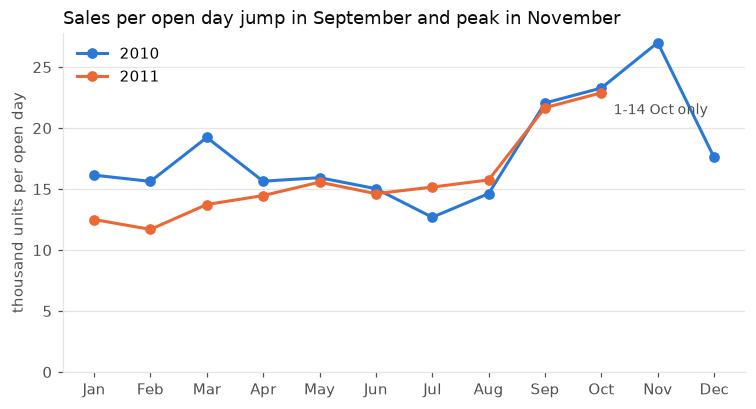

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for year, color in ((2010, BLUE), (2011, ORANGE)):
    part = monthly[monthly.index.year == year]
    ax.plot(
        part.index.month, part["per_day"] / 1000, marker="o", color=color, lw=2, label=str(year)
    )
ax.annotate(
    "1-14 Oct only",
    (10, monthly.loc["2011-10-01", "per_day"] / 1000),
    xytext=(8, -14),
    textcoords="offset points",
    color=MUTED,
    fontsize=9,
)
ax.set_xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
)
ax.set_ylabel("thousand units per open day")
ax.set_ylim(0, None)
ax.grid(axis="y", color=GRID)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Sales per open day jump in September and peak in November")
fig.savefig(FIG / "eda_season.png")

In [5]:
seasonal_lift(total).round(2)

2010    1.54
2011    1.55
Name: lift, dtype: float64

- Sep to Nov runs about 1.5 times the Jan to Aug level, in both years. Customers are mostly
  wholesalers, so they buy Christmas stock early. The peak is November, not December.
- No clear growth from 2010 to 2011: Jan to Aug 2011 is slightly *below* 2010 per open day.
- December is well below November even per open day: 17.6k vs 27.0k in 2010, and 20.0k in
  December 2009. So the dip is real, not only the closure; the Christmas buying is done by then.
- March 2010 is a one-off bump (19.2k); March 2011 doesn't repeat it. Not explained yet.

**What it means for the backtest:** the 26 weekly origins run from mid-April to mid-October,
so only the last few see the September jump. The holdout (15 Oct to 9 Dec) is all peak season.
Backtest errors will understate holdout errors, and a model that can't move with the season
will look better in the backtest than it is.

## Weekly pattern

In [6]:
weekdays = weekday_profile(total)
weekdays.round(2)

,mean,open_days,ratio
weekday,,,
0,19210.24,86,1.13
1,18825.19,96,1.11
2,17967.97,96,1.06
3,20963.49,95,1.23
4,15108.12,91,0.89
5,4843.00,1,0.29
6,9759.82,91,0.57


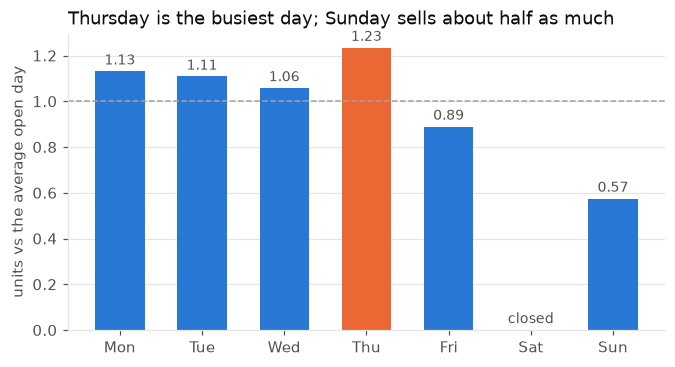

In [7]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ratio = weekdays["ratio"].where(weekdays["open_days"] >= 5)
bars = ax.bar(
    names, ratio.fillna(0), color=[ORANGE if d == 3 else BLUE for d in range(7)], width=0.6
)
for d, value in enumerate(ratio):
    label = "closed" if pd.isna(value) else f"{value:.2f}"
    ax.text(d, (0 if pd.isna(value) else value) + 0.03, label, ha="center", color=MUTED, fontsize=9)
ax.axhline(1, color=GRAY, lw=1, ls="--")
ax.set_ylabel("units vs the average open day")
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
ax.set_title("Thursday is the busiest day; Sunday sells about half as much")
fig.savefig(FIG / "eda_weekday.png")

- Saturday is closed (one Saturday in the data had sales; it's too few to plot).
- Sunday is about half a weekday, Friday a bit below average.
- A seasonal-naive baseline should therefore copy *the same weekday last week*, not yesterday.

## How erratic is each product?

Classed by how often it sells (ADI, open days per selling day) and how much the daily
amount varies when it does sell (CV²), with the Syntetos-Boylan cut-offs 1.32 and 0.49.

In [8]:
classes = demand_classes(wide)
classes["class"].value_counts()

class
erratic    94
lumpy       6
Name: count, dtype: int64

In [9]:
classes[["selling_days", "adi", "cv2"]].describe().round(2)

,selling_days,adi,cv2
count,100.00,100.00,100.00
mean,475.87,1.18,2.74
std,35.85,0.09,1.92
min,397.00,1.00,0.64
25%,446.50,1.12,1.49
50%,475.50,1.17,2.19
75%,498.00,1.25,3.30
max,555.00,1.40,13.08


All 100 sell on most open days (ADI 1.0 to 1.4), so zeros aren't the problem and Croston-type
methods for intermittent demand aren't needed. The size of each day's sales is: median CV² 2.2.

Large orders are 22% of all units (Day 2). How much of the variation do they cause?
Rebuild the same series without them:

In [10]:
raw = data.load()
sales, _ = clean(raw)
days = before_holdout(pd.DataFrame(index=open_days(raw))).index
products = [c for c in wide.columns if c != TOTAL]


def series_from(lines):
    lines = lines[lines["InvoiceDate"].dt.normalize().isin(days)]
    return daily_units(lines, days).reindex(columns=products, fill_value=0)


without_large = demand_classes(series_from(sales[~sales["large_order"]]))
pd.DataFrame(
    {
        "all sales": classes["cv2"].describe(),
        "without large orders": without_large["cv2"].describe(),
    }
).round(2)

,all sales,without large orders
count,100.00,100.00
mean,2.74,1.17
std,1.92,0.31
min,0.64,0.45
25%,1.49,1.00
50%,2.19,1.12
75%,3.30,1.28
max,13.08,2.04


In [11]:
without_large["class"].value_counts()

class
erratic    93
lumpy       6
smooth      1
Name: count, dtype: int64

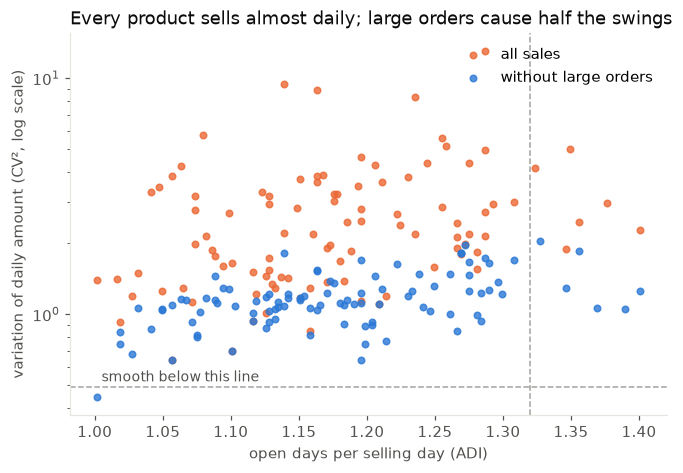

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(classes["adi"], classes["cv2"], s=18, color=ORANGE, label="all sales", alpha=0.8)
ax.scatter(
    without_large["adi"],
    without_large["cv2"],
    s=18,
    color=BLUE,
    label="without large orders",
    alpha=0.8,
)
ax.axhline(0.49, color=GRAY, lw=1, ls="--")
ax.axvline(1.32, color=GRAY, lw=1, ls="--")
ax.text(1.005, 0.52, "smooth below this line", color=MUTED, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("open days per selling day (ADI)")
ax.set_ylabel("variation of daily amount (CV², log scale)")
ax.legend(frameon=False, loc="upper right", scatterpoints=1)
ax.set_title("Every product sells almost daily; large orders cause half the swings")
fig.savefig(FIG / "eda_demand_classes.png")

- Removing large orders halves the median CV² (2.2 to about 1.1), but 99 of 100 products
  are still erratic or lumpy. Day-to-day size swings are normal here, not only the odd big order.
- Large orders are flagged, not removed (decision 5). Day 8 compares training with and
  without them; the error metric should be one a single 2,000-unit day can't dominate (wMAPE, MAE).

## Takeaways for Day 4

1. Seasonal-naive on the **same weekday last week** is the baseline to beat; naive (yesterday) will be hurt by Sundays.
2. Backtest origins mostly miss the September jump; read backtest errors as optimistic for the holdout.
3. Use MAE and wMAPE as the main metrics. RMSE gets driven by a few huge days.
4. No year-on-year growth to model; the season matters far more than the trend.